# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : M. Jabbarul Haq
- NIM   : 241011400606
- Kelas : **Reg B** ~~/ Reg C~~

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 6   # 2 digit terakhir NIM 241011400606 -> 06 -> 6

In [2]:
# Fungsi train_test_split (implementasi NumPy)
def train_test_split(X, y, test_size=0.25, random_state=None):
    """Membagi data secara acak menjadi data training dan testing."""
    X = np.asarray(X)
    y = np.asarray(y)
    n = len(X)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(n)            # acak urutan indeks
    n_test = int(round(n * test_size))      # jumlah data testing
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40

Shape X: (40, 1) | Shape y: (40,)


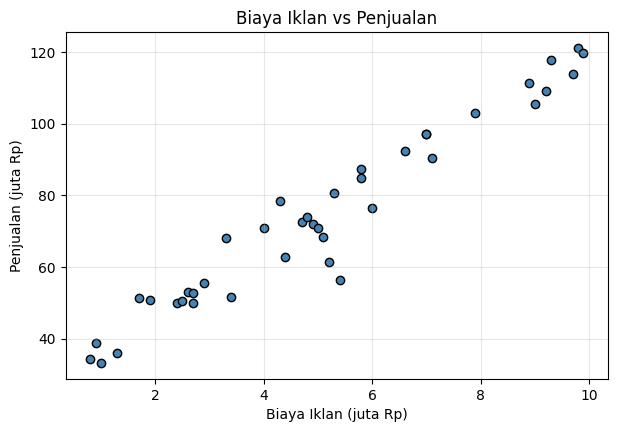

In [3]:
# Jawaban A1
df_ads = pd.read_csv("Ads_Data.csv")
print("5 data pertama:")
print(df_ads.head())
print("\nJumlah baris data:", len(df_ads))

# Pisahkan X (2 dimensi, bentuk (n,1)) dan y
X = df_ads[["BiayaIklan"]].values
y = df_ads["Penjualan"].values
print("\nShape X:", X.shape, "| Shape y:", y.shape)

# Scatter plot
plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, color="steelblue", edgecolor="k")
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None

    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]                 # tambah kolom bias
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y   # normal equation
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

lin_reg = LinearRegression().fit(X_train, y_train)
b_ne = lin_reg.intercept_
m_ne = lin_reg.coef_[0]
print(f"Intercept (b)  : {b_ne:.4f}")
print(f"Koefisien (m)  : {m_ne:.4f}")
print(f"Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * X")

Intercept (b)  : 29.4465
Koefisien (m)  : 9.0602
Persamaan      : y_hat = 29.4465 + 9.0602 * X


**Jawaban A3 (interpretasi):**

Persamaan regresinya adalah $\hat{y} = 29{,}4465 + 9{,}0602\,X$. Koefisien $m = 9{,}0602$ berarti setiap kenaikan biaya iklan sebesar 1 juta Rp diikuti kenaikan penjualan rata-rata sebesar sekitar 9,06 juta Rp, dengan asumsi faktor lain tetap. Intercept $b = 29{,}4465$ adalah perkiraan penjualan bila biaya iklan nol. Angka ini perlu hati-hati dibaca karena data biaya iklan terkecil adalah 0,8 juta, sehingga $X = 0$ berada di luar rentang data.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

pred_train = lin_reg.predict(X_train)
pred_test = lin_reg.predict(X_test)

hasil = pd.DataFrame({
    "MAE":  [mae(y_train, pred_train),  mae(y_test, pred_test)],
    "MSE":  [mse(y_train, pred_train),  mse(y_test, pred_test)],
    "RMSE": [rmse(y_train, pred_train), rmse(y_test, pred_test)],
    "R2":   [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
}, index=["Training", "Testing"])
print(hasil.round(4))
print("\nRata-rata Penjualan (y):", round(y.mean(), 2), "| Std:", round(y.std(), 2))

             MAE      MSE    RMSE      R2
Training  4.0854  26.9360  5.1900  0.9516
Testing   6.0650  77.2388  8.7886  0.9171

Rata-rata Penjualan (y): 74.27 | Std: 25.19


**Jawaban A4 (analisis):**

RMSE pada data training adalah 5,19 dan pada data testing 8,79 (dalam juta Rp). Artinya, rata-rata prediksi penjualan model meleset sekitar 5,2 juta pada data training dan sekitar 8,8 juta pada data testing. Sebagai pembanding, rata-rata penjualan adalah 74,27 juta, sehingga galat pada data testing sekitar 12% dari rata-rata penjualan. Nilai $R^2$ sebesar 0,9516 (training) dan 0,9171 (testing) berarti sekitar 95% dan 92% variasi penjualan bisa dijelaskan oleh biaya iklan.

Menurut saya model ini sudah baik karena $R^2$ tinggi baik di training maupun testing, dan jaraknya tidak jauh (selisih sekitar 0,03), sehingga tidak ada tanda overfitting yang serius. Error testing sedikit lebih besar dari training, yang wajar karena model dilatih pada data training. Perlu dicatat juga bahwa data testing hanya 8 titik, jadi angkanya cukup sensitif terhadap pembagian data.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Normal Equation  : b = 29.4465, m = 9.0602

LR = 0.001  -> b = 25.6672, m = 9.6621, loss akhir = 29.8341
LR = 0.02   -> b = 29.4465, m = 9.0602, loss akhir = 26.9360
LR = 0.1    -> b = nan, m = nan, loss akhir = nan
LR = 0.001: loss selalu berhingga; iterasi 100 = 166.6708, iterasi 1000 = 95.4950, akhir = 29.8341
LR = 0.02: loss selalu berhingga; iterasi 100 = 57.8316, iterasi 1000 = 26.9360, akhir = 26.9360
LR = 0.1: loss menjadi inf/NaN mulai iterasi ke-205  (loss iterasi 10 = 4.245e+18, iterasi 50 = 1.052e+78)


cell17:19: RuntimeWarning: overflow encountered in square
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
cell17:20: RuntimeWarning: overflow encountered in matmul
cell17:22: RuntimeWarning: invalid value encountered in subtract


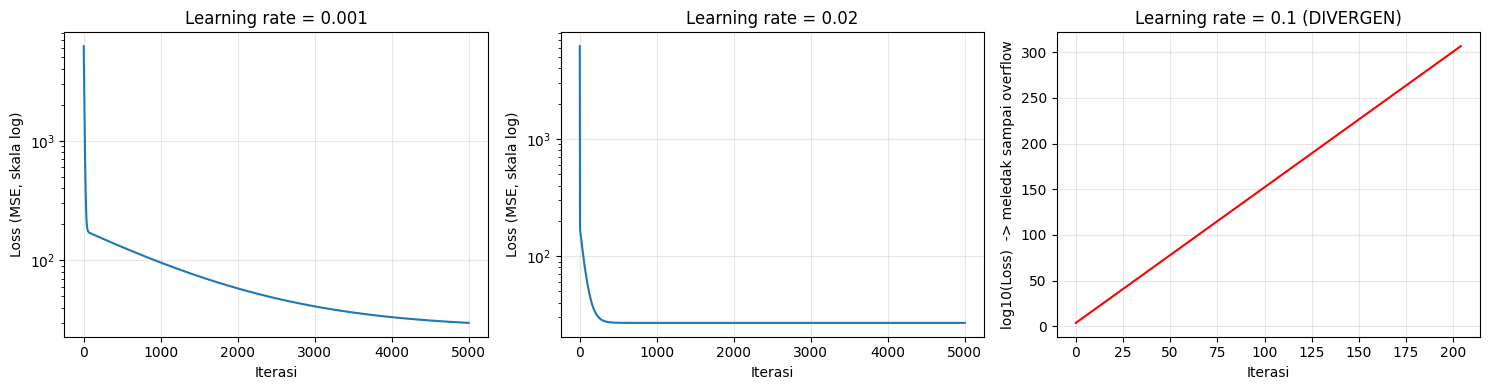

In [7]:
# Jawaban A5
class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history = []

    def fit(self, X, y):
        n, d = X.shape
        self.coef_ = np.zeros(d)
        self.intercept_ = 0.0
        self.loss_history = []
        for _ in range(self.n_iter):
            y_pred = self.intercept_ + X @ self.coef_
            error = y_pred - y
            self.loss_history.append(np.mean(error ** 2))      # MSE
            grad_w = (2 / n) * (X.T @ error)
            grad_b = (2 / n) * np.sum(error)
            self.coef_ = self.coef_ - self.lr * grad_w
            self.intercept_ = self.intercept_ - self.lr * grad_b
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

learning_rates = [0.001, 0.02, 0.1]
models_gd = {}
print(f"Normal Equation  : b = {b_ne:.4f}, m = {m_ne:.4f}\n")
for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    models_gd[lr] = gd
    print(f"LR = {lr:<6} -> b = {gd.intercept_:.4f}, m = {gd.coef_[0]:.4f}, loss akhir = {gd.loss_history[-1]:.4f}")

# Cari iterasi saat loss mulai tidak terhingga / NaN (divergen)
for lr in learning_rates:
    h = np.array(models_gd[lr].loss_history)
    bad = np.where(~np.isfinite(h))[0]
    if len(bad) > 0:
        print(f"LR = {lr}: loss menjadi inf/NaN mulai iterasi ke-{bad[0]}  (loss iterasi 10 = {h[10]:.3e}, iterasi 50 = {h[50]:.3e})")
    else:
        print(f"LR = {lr}: loss selalu berhingga; iterasi 100 = {h[100]:.4f}, iterasi 1000 = {h[1000]:.4f}, akhir = {h[-1]:.4f}")

# Grafik loss vs iterasi (nilai inf/NaN tidak bisa digambar, jadi hanya bagian yang berhingga)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    h = np.array(models_gd[lr].loss_history)
    if np.isfinite(h[-1]):
        ax.plot(h)
        ax.set_yscale("log")
        ax.set_title(f"Learning rate = {lr}")
        ax.set_ylabel("Loss (MSE, skala log)")
    else:
        # divergen: loss meledak hingga 1e300, jadi digambar dalam log10(loss)
        ok = np.isfinite(h) & (h > 0)
        ax.plot(np.where(ok, np.log10(np.where(ok, h, 1)), np.nan), color="red")
        ax.set_title(f"Learning rate = {lr} (DIVERGEN)")
        ax.set_ylabel("log10(Loss)  -> meledak sampai overflow")
    ax.set_xlabel("Iterasi")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

Hasil normal equation adalah $b = 29{,}4465$ dan $m = 9{,}0602$.

- **Learning rate 0,001 (terlalu lambat).** Setelah 5000 iterasi hasilnya $b = 25{,}6672$ dan $m = 9{,}6621$ dengan loss 29,83, masih berbeda dari solusi normal equation (loss 26,94). Grafiknya menunjukkan loss turun sangat landai dan belum mendatar, jadi model belum konvergen. Langkah update-nya terlalu kecil sehingga butuh jauh lebih banyak iterasi.
- **Learning rate 0,02 (pas).** Hasilnya $b = 29{,}4465$ dan $m = 9{,}0602$, sama persis dengan normal equation, dan loss turun cepat lalu mendatar sekitar iterasi 500.
- **Learning rate 0,1 (divergen).** Hasil akhirnya `nan`. Loss malah membesar sangat cepat, sudah sekitar $4 \times 10^{18}$ pada iterasi ke-10 dan menjadi `inf`/`NaN` mulai iterasi ke-205. Ini terlihat dari grafik log10(loss) yang naik terus sampai sekitar 300.

Peringatan `RuntimeWarning: overflow` berarti nilai angkanya sudah melewati batas terbesar yang bisa disimpan tipe float, akibat parameter yang terus membesar. Penyebabnya adalah langkah update terlalu besar sehingga setiap iterasi melompati titik minimum dan mendarat di sisi seberang dengan loss yang lebih besar, lalu terus membesar. Fitur `BiayaIklan` juga tidak diskalakan (nilainya sampai ~10), sehingga gradiennya besar dan batas learning rate yang aman menjadi kecil.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

Biaya iklan  4.5 juta -> prediksi penjualan = 70.22 juta
Biaya iklan  7.0 juta -> prediksi penjualan = 92.87 juta
Biaya iklan 12.0 juta -> prediksi penjualan = 138.17 juta

Rentang BiayaIklan pada data: 0.8 s.d. 9.9 juta


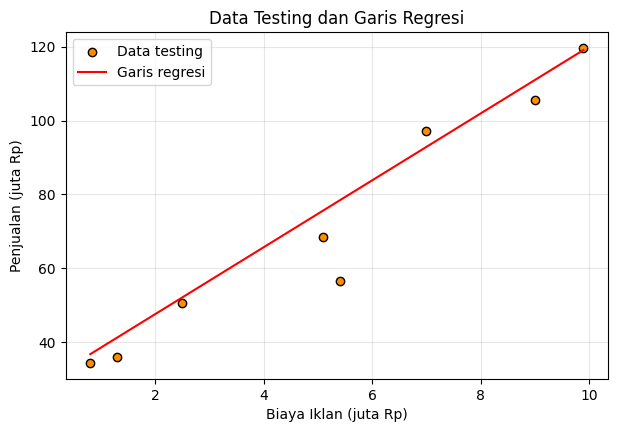

In [8]:
# Jawaban A6
# 1. Scatter data testing + garis regresi (Normal Equation)
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test, y_test, color="darkorange", edgecolor="k", label="Data testing")
plt.plot(x_line, lin_reg.predict(x_line), color="red", label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Prediksi
biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = lin_reg.predict(biaya_baru)
for biaya, p in zip(biaya_baru.ravel(), pred_baru):
    print(f"Biaya iklan {biaya:>4} juta -> prediksi penjualan = {p:.2f} juta")
print("\nRentang BiayaIklan pada data: {:.1f} s.d. {:.1f} juta".format(X.min(), X.max()))

**Jawaban A6 (analisis):**

Prediksi penjualan untuk biaya iklan 4,5 juta, 7 juta, dan 12 juta berturut-turut adalah 70,22 juta, 92,87 juta, dan 138,17 juta. Dua prediksi pertama berada di dalam rentang data (0,8 sampai 9,9 juta) sehingga cukup bisa dipercaya, karena di rentang itu hubungan biaya iklan dan penjualan terlihat linear pada scatter plot.

Prediksi untuk 12 juta adalah ekstrapolasi karena nilainya di atas biaya iklan terbesar pada data (9,9 juta), dan penjualan tertinggi yang pernah terjadi 121,1 juta. Hasil 138,17 juta hanya benar bila hubungan linear tetap berlaku di luar rentang data. Padahal di dunia nyata efek iklan biasanya menurun pada biaya yang sangat besar (pasar mulai jenuh), sehingga model bisa melebih-lebihkan penjualan. Karena model tidak punya data di area itu, saya hanya menganggapnya perkiraan kasar dan kurang bisa dipercaya.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah email per kelas:
Spam
Bukan Spam (0)    35
Spam (1)          25
Name: count, dtype: int64

Shape X: (60, 2) | Shape y: (60,)


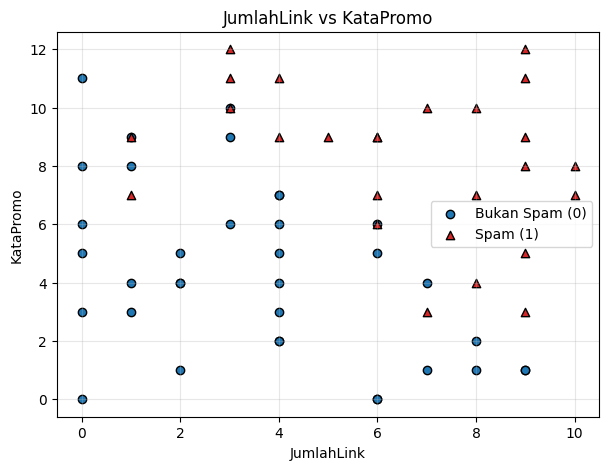

In [9]:
# Jawaban B1
df_mail = pd.read_csv("Email_Data.csv")
print("5 data pertama:")
print(df_mail.head())
print("\nJumlah email per kelas:")
print(df_mail["Spam"].value_counts().rename({0: "Bukan Spam (0)", 1: "Spam (1)"}))

X_m = df_mail[["JumlahLink", "KataPromo"]].values
y_m = df_mail["Spam"].values
print("\nShape X:", X_m.shape, "| Shape y:", y_m.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_m[y_m == 0, 0], X_m[y_m == 0, 1], color="tab:blue", edgecolor="k", label="Bukan Spam (0)")
plt.scatter(X_m[y_m == 1, 0], X_m[y_m == 1, 1], color="tab:red", marker="^", edgecolor="k", label="Spam (1)")
plt.title("JumlahLink vs KataPromo")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Train: (45, 2) | Test: (15, 2)

Intercept (b)    : -9.5523
Koefisien m1     : 0.8454  (JumlahLink)
Koefisien m2     : 0.8687  (KataPromo)
P(Spam) = sigmoid(-9.5523 + 0.8454*JumlahLink + 0.8687*KataPromo)

Log loss: awal = 0.6931, iterasi 1000 = 0.3400, iterasi 5000 = 0.2978, akhir = 0.2959


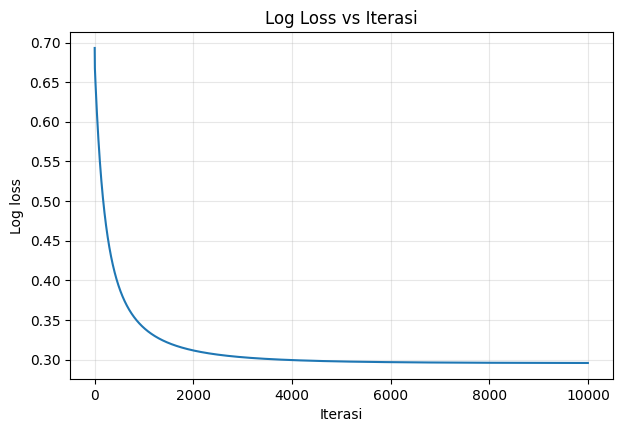

In [10]:
# Jawaban B2
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_m, y_m, test_size=0.25, random_state=RANDOM_STATE)
print("Train:", Xm_train.shape, "| Test:", Xm_test.shape)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    """Logistic Regression dengan Gradient Descent (loss = log loss)."""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history = []

    def fit(self, X, y):
        n, d = X.shape
        self.coef_ = np.zeros(d)
        self.intercept_ = 0.0
        self.loss_history = []
        eps = 1e-12
        for _ in range(self.n_iter):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
            self.loss_history.append(loss)
            error = p - y
            self.coef_ = self.coef_ - self.lr * (X.T @ error) / n
            self.intercept_ = self.intercept_ - self.lr * np.mean(error)
        return self

    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xm_train, ym_train)
b_log = log_reg.intercept_
m1, m2 = log_reg.coef_
print(f"\nIntercept (b)    : {b_log:.4f}")
print(f"Koefisien m1     : {m1:.4f}  (JumlahLink)")
print(f"Koefisien m2     : {m2:.4f}  (KataPromo)")
print(f"P(Spam) = sigmoid({b_log:.4f} + {m1:.4f}*JumlahLink + {m2:.4f}*KataPromo)")
print(f"\nLog loss: awal = {log_reg.loss_history[0]:.4f}, iterasi 1000 = {log_reg.loss_history[999]:.4f}, "
      f"iterasi 5000 = {log_reg.loss_history[4999]:.4f}, akhir = {log_reg.loss_history[-1]:.4f}")

plt.figure(figsize=(7, 4.5))
plt.plot(log_reg.loss_history)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.grid(alpha=0.3)
plt.show()

**Jawaban B2 (analisis):**

Persamaan yang diperoleh adalah $P(\text{Spam}) = \sigma(-9{,}5523 + 0{,}8454 \cdot \text{JumlahLink} + 0{,}8687 \cdot \text{KataPromo})$. Kedua koefisien positif, artinya semakin banyak link dan kata promosi, semakin besar peluang email dianggap spam. Setiap tambahan satu link mengalikan odds spam sekitar $e^{0{,}8454} \approx 2{,}33$ kali, dan setiap tambahan satu kata promosi sekitar $e^{0{,}8687} \approx 2{,}38$ kali.

Pada grafik, loss sudah turun dan stabil. Nilainya mulai dari 0,6931 (sama dengan $\ln 2$, karena awalnya semua parameter nol sehingga $P = 0{,}5$), turun menjadi 0,3400 pada iterasi 1000, 0,2978 pada iterasi 5000, dan 0,2959 di akhir (iterasi 10000). Penurunan di paruh kedua sudah sangat kecil, sekitar 0,002, sehingga model sudah hampir konvergen.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    """Return [[TN, FP], [FN, TP]]"""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

y_pred_m = log_reg.predict(Xm_test)           # threshold default 0.5
cm = confusion_matrix(ym_test, y_pred_m)
print(f"Accuracy  : {accuracy_score(ym_test, y_pred_m):.4f}")
print(f"Precision : {precision_score(ym_test, y_pred_m):.4f}")
print(f"Recall    : {recall_score(ym_test, y_pred_m):.4f}")
print(f"F1-score  : {f1_score(ym_test, y_pred_m):.4f}")
print("\nConfusion matrix (baris = aktual, kolom = prediksi):")
print(pd.DataFrame(cm, index=["Aktual 0", "Aktual 1"], columns=["Pred 0", "Pred 1"]))
print(f"\nTN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}")

Accuracy  : 0.9333
Precision : 0.8000
Recall    : 1.0000
F1-score  : 0.8889

Confusion matrix (baris = aktual, kolom = prediksi):
          Pred 0  Pred 1
Aktual 0      10       1
Aktual 1       0       4

TN=10, FP=1, FN=0, TP=4


**Jawaban B3 (analisis):**

Pada data testing (15 email) diperoleh accuracy 0,9333, precision 0,8000, recall 1,0000, dan F1-score 0,8889. Confusion matrix-nya: TN = 10, FP = 1, FN = 0, TP = 4. Jadi dari 4 email spam, semuanya berhasil terdeteksi, dan dari 11 email normal, 1 salah dianggap spam.

**FP (false positive)** berarti email normal yang salah diklasifikasikan sebagai spam. **FN (false negative)** berarti email spam yang lolos ke inbox. Menurut saya FP lebih merugikan pengguna, karena email penting (misalnya informasi kuliah, pekerjaan, atau tagihan) bisa masuk folder spam dan tidak terbaca. FN hanya membuat inbox kemasukan email yang mengganggu, tetapi pengguna masih bisa menghapusnya sendiri.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-9.5523 + 0.8454 * JumlahLink) / 0.8687
                   KataPromo = 10.9960 + -0.9731 * JumlahLink
Jumlah data testing yang salah diklasifikasikan: 1 dari 15
 JumlahLink  KataPromo  Aktual  Prediksi  P(Spam)
          3         10       0         1   0.8417


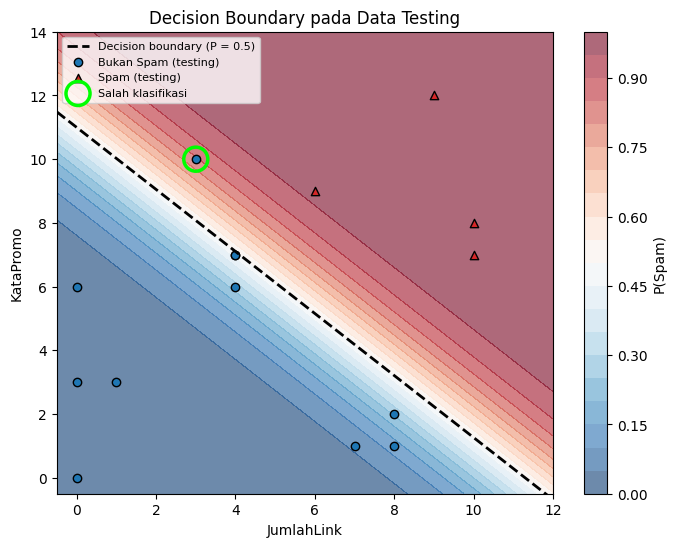

In [12]:
# Jawaban B4
# Persamaan decision boundary: x2 = -(b + m1*x1) / m2
print(f"Decision boundary: KataPromo = -({b_log:.4f} + {m1:.4f} * JumlahLink) / {m2:.4f}")
print(f"                   KataPromo = {-b_log/m2:.4f} + {-m1/m2:.4f} * JumlahLink")

# Background probabilitas
x1_grid, x2_grid = np.meshgrid(np.linspace(-0.5, 12, 300), np.linspace(-0.5, 14, 300))
grid = np.c_[x1_grid.ravel(), x2_grid.ravel()]
prob_grid = log_reg.predict_proba(grid).reshape(x1_grid.shape)

salah = y_pred_m != ym_test      # data yang salah klasifikasi
plt.figure(figsize=(8, 6))
cf = plt.contourf(x1_grid, x2_grid, prob_grid, levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(cf, label="P(Spam)")
x1_line = np.linspace(-0.5, 12, 100)
plt.plot(x1_line, -(b_log + m1 * x1_line) / m2, "k--", linewidth=2, label="Decision boundary (P = 0.5)")
plt.scatter(Xm_test[ym_test == 0, 0], Xm_test[ym_test == 0, 1], color="tab:blue", edgecolor="k", label="Bukan Spam (testing)")
plt.scatter(Xm_test[ym_test == 1, 0], Xm_test[ym_test == 1, 1], color="tab:red", marker="^", edgecolor="k", label="Spam (testing)")
plt.scatter(Xm_test[salah, 0], Xm_test[salah, 1], s=300, facecolors="none", edgecolors="lime", linewidths=2.5, label="Salah klasifikasi")
plt.xlim(-0.5, 12); plt.ylim(-0.5, 14)
plt.title("Decision Boundary pada Data Testing")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(loc="upper left", fontsize=8)
plt.show()

print("Jumlah data testing yang salah diklasifikasikan:", salah.sum(), "dari", len(ym_test))
if salah.sum() > 0:
    df_salah = pd.DataFrame({
        "JumlahLink": Xm_test[salah, 0], "KataPromo": Xm_test[salah, 1],
        "Aktual": ym_test[salah], "Prediksi": y_pred_m[salah],
        "P(Spam)": log_reg.predict_proba(Xm_test[salah]).round(4)})
    print(df_salah.to_string(index=False))

**Jawaban B4 (analisis):**

Persamaan decision boundary-nya adalah $x_2 = 10{,}9960 - 0{,}9731\,x_1$, yaitu KataPromo $= 10{,}996 - 0{,}9731 \times$ JumlahLink. Garis ini berarti bahwa email dengan jumlah link + kata promo sekitar 11 berada di perbatasan; di atas garis diprediksi Spam dan di bawahnya Bukan Spam.

Dari 15 data testing hanya 1 yang salah diklasifikasikan (dilingkari hijau pada grafik), yaitu email dengan JumlahLink = 3 dan KataPromo = 10. Email ini aslinya Bukan Spam, tetapi model memberi P(Spam) = 0,8417 sehingga diprediksi Spam (false positive). Titik ini berada di atas garis karena jumlah kata promonya tinggi, padahal link-nya sedikit, jadi model yang hanya berupa garis lurus tidak bisa membedakannya.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
proba_test = log_reg.predict_proba(Xm_test)
baris = []
for t in [0.3, 0.5, 0.7]:
    yp = (proba_test >= t).astype(int)
    cm_t = confusion_matrix(ym_test, yp)
    baris.append({"Threshold": t, "TN": cm_t[0, 0], "FP": cm_t[0, 1], "FN": cm_t[1, 0], "TP": cm_t[1, 1],
                  "Accuracy": accuracy_score(ym_test, yp),
                  "Precision": precision_score(ym_test, yp),
                  "Recall": recall_score(ym_test, yp)})
tabel_threshold = pd.DataFrame(baris).set_index("Threshold")
print(tabel_threshold.round(4))

           TN  FP  FN  TP  Accuracy  Precision  Recall
Threshold                                             
0.3         8   3   0   4    0.8000     0.5714     1.0
0.5        10   1   0   4    0.9333     0.8000     1.0
0.7        10   1   0   4    0.9333     0.8000     1.0


**Jawaban B5 (analisis):**

Menurunkan threshold (0,3) membuat model lebih mudah memberi label Spam, sehingga recall naik atau tetap, tetapi precision turun karena lebih banyak email normal ikut terblokir. Terlihat dari tabel: pada threshold 0,3 terdapat 3 FP, precision turun menjadi 0,5714 dan accuracy 0,80. Menaikkan threshold (0,7) membuat model lebih ketat sehingga FP berkurang dan precision naik, tetapi berisiko menambah FN (recall turun). Pada data ini recall tetap 1,0 di ketiga threshold karena keempat email spam di data testing punya probabilitas yang tinggi, dan hasil threshold 0,5 dan 0,7 sama persis (FP = 1, precision = 0,8, accuracy = 0,9333).

Berdasarkan Soal B3, FP lebih merugikan, maka saya memilih **threshold 0,7**. Pada data testing hasilnya sama baiknya dengan 0,5 (recall tetap 1,0), tetapi threshold ini memberi batas yang lebih aman, yaitu email yang ragu-ragu (probabilitas 0,5 sampai 0,7) tidak langsung diblokir. Saya tidak memilih threshold yang jauh lebih tinggi karena data testing hanya 15 email, sehingga belum cukup bukti untuk menyimpulkan bahwa spam tidak akan mulai lolos.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
THRESHOLD_PILIHAN = 0.7    # threshold pilihan dari Soal B5 (alasan ada di analisis B5)

email_baru = pd.DataFrame({"Email": ["E1", "E2", "E3", "E4"],
                           "JumlahLink": [1, 5, 9, 2],
                           "KataPromo": [2, 6, 10, 11]})
p_baru = log_reg.predict_proba(email_baru[["JumlahLink", "KataPromo"]].values)
email_baru["P(Spam)"] = p_baru.round(4)
email_baru["Prediksi"] = np.where(p_baru >= THRESHOLD_PILIHAN, "Spam", "Bukan Spam")
print(f"Threshold yang dipakai: {THRESHOLD_PILIHAN}\n")
print(email_baru.to_string(index=False))

Threshold yang dipakai: 0.7

Email  JumlahLink  KataPromo  P(Spam)   Prediksi
   E1           1          2   0.0009 Bukan Spam
   E2           5          6   0.4717 Bukan Spam
   E3           9         10   0.9988       Spam
   E4           2         11   0.8448       Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena targetnya adalah kelas (0 atau 1), bukan nilai kontinu. Model hanya "regresi" dalam arti ia menghitung kombinasi linear $z = b + m_1 x_1 + m_2 x_2$ terlebih dahulu. Fungsi sigmoid $\sigma(z) = 1/(1+e^{-z})$ lalu mengubah $z$ (bisa bernilai berapa pun) menjadi probabilitas antara 0 dan 1. Probabilitas ini kemudian dibandingkan dengan threshold (misalnya 0,5) untuk menentukan kelas.

**Jawaban C2:**
Normal equation menghitung parameter langsung dengan rumus $\theta = (X^TX)^{-1}X^Ty$ dalam sekali hitung, tanpa learning rate dan iterasi, sehingga hasilnya eksak. Gradient descent memperbarui parameter sedikit demi sedikit mengikuti arah turunnya loss, sehingga butuh learning rate dan jumlah iterasi yang tepat (seperti terlihat di Soal A5). Gradient descent sebaiknya dipakai jika fiturnya sangat banyak atau datanya sangat besar (karena invers matriks mahal), atau untuk model yang tidak punya rumus langsung, seperti Logistic Regression.

**Jawaban C3:**
Model dilatih agar cocok dengan data training, jadi performanya di data training cenderung terlalu optimis. Data testing adalah data yang belum pernah dilihat model, sehingga dipakai untuk mengukur kemampuan generalisasi. Overfitting adalah kondisi ketika model terlalu menghafal data training (termasuk noise) sehingga performanya bagus di training tetapi jauh lebih buruk di data baru. Pada tugas ini, $R^2$ training 0,9516 dan testing 0,9171 hanya berbeda sedikit, jadi model tidak overfitting secara serius.

**Jawaban C4:**
Linear Regression memprediksi nilai kontinu, sehingga ukuran kesalahan yang wajar adalah selisih kuadrat antara nilai prediksi dan nilai sebenarnya (MSE). Logistic Regression menghasilkan probabilitas untuk label 0/1, sehingga yang diukur adalah seberapa yakin model pada kelas yang benar, dan itu yang dilakukan log loss. Log loss memberi hukuman sangat besar saat model yakin tetapi salah (misal memberi $P = 0{,}01$ padahal kelas sebenarnya 1). Jika MSE dipakai dengan sigmoid, fungsi loss-nya tidak cembung dan gradiennya mengecil, sehingga training jadi lebih sulit.

**Jawaban C5:**
Salah satu penyebab utamanya adalah `random_state` yang saya pakai berasal dari 2 digit terakhir NIM, sehingga pembagian data training dan testing berbeda untuk tiap mahasiswa. Data training yang berbeda menghasilkan koefisien yang sedikit berbeda, dan data testing yang berbeda menghasilkan metrik (akurasi, $R^2$, dan lain-lain) yang berbeda pula. Karena dataset ini kecil (40 dan 60 baris), perbedaan pembagian data berpengaruh cukup terasa. Pada gradient descent, pilihan learning rate dan jumlah iterasi juga ikut memengaruhi hasil akhirnya.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinReg
from sklearn.linear_model import LogisticRegression as SkLogReg

# --- Linear Regression ---
sk_lin = SkLinReg().fit(X_train, y_train)
print("=== Linear Regression ===")
print(f"Implementasi sendiri : b = {b_ne:.4f}, m = {m_ne:.4f}, R2 test = {r2_score(y_test, pred_test):.4f}")
print(f"scikit-learn         : b = {sk_lin.intercept_:.4f}, m = {sk_lin.coef_[0]:.4f}, "
      f"R2 test = {r2_score(y_test, sk_lin.predict(X_test)):.4f}")

# --- Logistic Regression ---
sk_log_default = SkLogReg().fit(Xm_train, ym_train)                  # default: L2 penalty, C=1.0
sk_log_noreg = SkLogReg(C=1e10, max_iter=100000).fit(Xm_train, ym_train)   # hampir tanpa regularisasi

def ringkas(nama, b, m, model_pred):
    return {"Model": nama, "b": b, "m1 (Link)": m[0], "m2 (Promo)": m[1],
            "Accuracy": accuracy_score(ym_test, model_pred),
            "Precision": precision_score(ym_test, model_pred),
            "Recall": recall_score(ym_test, model_pred),
            "F1": f1_score(ym_test, model_pred)}

tabel_bonus = pd.DataFrame([
    ringkas("Implementasi sendiri", b_log, log_reg.coef_, y_pred_m),
    ringkas("sklearn (default, C=1)", sk_log_default.intercept_[0], sk_log_default.coef_[0], sk_log_default.predict(Xm_test)),
    ringkas("sklearn (C=1e10, tanpa reg.)", sk_log_noreg.intercept_[0], sk_log_noreg.coef_[0], sk_log_noreg.predict(Xm_test)),
]).set_index("Model")
print("\n=== Logistic Regression ===")
print(tabel_bonus.round(4).to_string())

=== Linear Regression ===
Implementasi sendiri : b = 29.4465, m = 9.0602, R2 test = 0.9171
scikit-learn         : b = 29.4465, m = 9.0602, R2 test = 0.9171

=== Logistic Regression ===
                                   b  m1 (Link)  m2 (Promo)  Accuracy  Precision  Recall      F1
Model                                                                                           
Implementasi sendiri         -9.5523     0.8454      0.8687    0.9333        0.8     1.0  0.8889
sklearn (default, C=1)       -8.7835     0.7740      0.7993    0.9333        0.8     1.0  0.8889
sklearn (C=1e10, tanpa reg.) -9.8984     0.8757      0.8992    0.9333        0.8     1.0  0.8889


**Jawaban Bonus (analisis):**

**Linear Regression:** hasil scikit-learn sama persis dengan implementasi saya ($b = 29{,}4465$, $m = 9{,}0602$, $R^2$ testing 0,9171), karena keduanya sama-sama menyelesaikan kuadrat terkecil secara eksak.

**Logistic Regression:** koefisien scikit-learn dengan pengaturan default ($b = -8{,}7835$, $m_1 = 0{,}7740$, $m_2 = 0{,}7993$) berbeda dengan implementasi saya ($b = -9{,}5523$, $m_1 = 0{,}8454$, $m_2 = 0{,}8687$). Penyebab utamanya adalah scikit-learn secara default memakai **regularisasi L2** (`penalty="l2"`, `C=1.0`) yang menahan koefisien agar tidak terlalu besar, sedangkan implementasi saya tidak memakai regularisasi. Ketika regularisasi hampir dimatikan (`C=1e10`), koefisiennya ($b = -9{,}8984$, $m_1 = 0{,}8757$, $m_2 = 0{,}8992$) menjadi jauh lebih dekat dengan milik saya. Sisa selisihnya wajar karena gradient descent saya berhenti pada 10000 iterasi (loss masih turun sangat pelan), sedangkan scikit-learn memakai solver `lbfgs` yang berjalan sampai konvergen.

Walaupun koefisiennya berbeda, accuracy (0,9333), precision (0,8), recall (1,0), dan F1 (0,8889) pada data testing sama untuk ketiganya, karena perbedaan koefisien yang kecil tidak mengubah keputusan klasifikasi pada 15 data testing.